# Butadiene: Rotation and Conjugation

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4v2/blob/main/ch4/4C-butadiene/ch4C-butadiene-v2.ipynb)
:::

We optimize *s-trans* and *s-cis*-butadiene, scan the central C&ndash;C torsion, find the transition state for rotation, and look at the &pi; orbitals of the flat and the twisted (90&deg;) molecule. Every energy is kept in *Python* as it is calculated. We never search the output files.

## Learning Goals

1.	**Optimize** the *s-trans* and *s-cis* conformers, and escape a **symmetry** trap.
2.	**Store** the results of each calculation in a *Python* table.
3.	**Scan** the central torsion to build a rotational energy profile.
4.	**Optimize** and **confirm** a transition state.
5.	**Compare** the &pi; orbitals of conjugated (flat) and unconjugated (90&deg;) butadiene.
6.	**Estimate** an equilibrium constant and a rate constant.

In [1]:
####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path
import sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Install packages only if needed
# Google Colab does not include every Python package
#
# Psi4 cannot be installed with pip. On Colab we first install conda
# (condacolab), which RESTARTS the session. After the restart, run
# this cell again and Psi4 will be installed with conda.
try:                  # if the package exists import it, otherwise install it
    import psi4
except ImportError:
    if IN_COLAB:
        !pip -q install condacolab
        import condacolab
        condacolab.install()
        !mamba install -q -y -c conda-forge psi4
    import psi4

try:
    import py3Dmol
except ImportError:
    !pip -q install py3Dmol
    import py3Dmol

try:
    import skimage          # scikit-image draws the static orbital and density surfaces
except ImportError:
    !pip -q install scikit-image
    import skimage

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Style sheets and helper functions from the book's GitHub repository
if IN_COLAB and not Path("styles/tufte.mplstyle").exists():
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/styles/tufte.mplstyle
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/styles/S2_classic2.mplstyle
    !wget -q -N https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/psi4_helpers.py

if IN_COLAB:
    plt.style.use("styles/tufte.mplstyle")
else:
    sys.path.insert(0, "../..")                 # psi4_helpers.py is two folders up
    plt.style.use("../../styles/tufte.mplstyle")

import psi4_helpers as ph

# Psi4 output (.out, .log, .molden, cube files, scans) goes into output/, which is not kept in git.
# Small results files that another page reads (.json, .csv) go into data/, which is kept in git.
output_dir = Path("output")
output_dir.mkdir(parents=True, exist_ok=True)
data_dir = Path("data")
data_dir.mkdir(parents=True, exist_ok=True)

# 3D pictures: False = static images (as in the book); True = rotatable py3Dmol viewers
INTERACTIVE = False

In [2]:
# Resources for every calculation on this page (house limits: 4 GB, 4 threads)
psi4.set_memory("4 GB")
psi4.set_num_threads(4)

# Exact (non-density-fitted) integrals
psi4.set_options({"scf_type": "pk"})

# Every result goes into this dictionary, filed under a name
results = {}

def record(name, energy, mol, steps=None):
    """Store the energy, central torsion and number of steps of one calculation."""
    results[name] = {"Energy (Eh)": energy,
                     "Torsion (deg)": round(ph.dihedral(mol, 4, 3, 2, 1), 2),
                     "Steps": steps}


  Memory set to   3.725 GiB by Python driver.
  Threads set to 4 by Python driver.


| Line | Notes |
| :---- | :---- |
| `results = {}` | An empty **dictionary**. Each calculation adds one entry to it. |
| `def record(...)` | Files the **energy**, the C4&ndash;C3&ndash;C2&ndash;C1 **torsion** and the number of **steps** under a name of our choosing. |

## Building Butadiene

In [3]:
# Butadiene from a Z-matrix. We choose the C4-C3-C2-C1 torsion, how far to twist
# the end hydrogens out of the plane (tweak), and the point group Psi4 may use
def make_butadiene(torsion, tweak=0.0, symmetry="c1"):
    return psi4.geometry(f"""
0 1
C
C   1    1.54000
C   2    1.54000  1 120.0000
C   3    1.54000  2 120.0000  1 {torsion}
H   1    1.14000  2 120.0000  3 {0 + tweak}
H   1    1.14000  5 120.0000  2 {180 - tweak}
H   2    1.14000  1 120.0000  3 {180 - tweak}
H   3    1.14000  4 120.0000  2 {180 - tweak}
H   4    1.14000  3 120.0000  7 {0 + tweak}
H   4    1.14000  9 120.0000  3 {180 - tweak}
symmetry {symmetry}
""")

## Optimizing the *s-trans* and *s-cis* Conformers

Four optimizations: flat *s-trans* (*C<sub>2h</sub>*), flat *s-cis* (*C<sub>2v</sub>*), and both again with the torsions **tweaked** 5&deg; away from flat and no symmetry.

In [4]:
# Flat s-trans, keeping its C2h symmetry
trans = make_butadiene(180.0, symmetry="c2h")
ph.new_output(output_dir / "bd_trans.out")
E, hist = psi4.optimize("hf/3-21g", molecule=trans, return_history=True)
record("s-trans (flat)", E, trans, len(hist["energy"]))

# Flat s-cis, keeping its C2v symmetry
cis_flat = make_butadiene(0.0, symmetry="c2v")
ph.new_output(output_dir / "bd_cis_flat.out")
E, hist = psi4.optimize("hf/3-21g", molecule=cis_flat, return_history=True)
record("s-cis (flat)", E, cis_flat, len(hist["energy"]))

# s-cis with the symmetry broken
cis = make_butadiene(5.0, tweak=5.0)
ph.new_output(output_dir / "bd_cis.out")
E, hist_cis = psi4.optimize("hf/3-21g", molecule=cis, return_history=True)
record("s-cis", E, cis, len(hist_cis["energy"]))

# s-trans with the symmetry broken
trans_tweak = make_butadiene(175.0, tweak=5.0)
ph.new_output(output_dir / "bd_trans_tweak.out")
E, hist = psi4.optimize("hf/3-21g", molecule=trans_tweak, return_history=True)
record("s-trans (tweaked)", E, trans_tweak, len(hist["energy"]))

# Show what we have so far, with energies relative to flat s-trans in kJ/mol
table = pd.DataFrame(results).T
table["Delta E (kJ/mol)"] = ((table["Energy (Eh)"] - results["s-trans (flat)"]["Energy (Eh)"])
                             * psi4.constants.hartree2kJmol)
table

Optimizer: Optimization complete!


Optimizer: Optimization complete!


Optimizer: Optimization complete!


Optimizer: Optimization complete!


,Energy (Eh),Torsion (deg),Steps,Delta E (kJ/mol)
s-trans (flat),-154.059456,180.00,8.0,0.000000
s-cis (flat),-154.053943,0.00,9.0,14.474404
s-cis,-154.055140,38.15,20.0,11.331740
s-trans (tweaked),-154.059456,-179.98,16.0,-0.000432


| Line | Notes |
| :---- | :---- |
| `ph.new_output(...)` | Sends the *Psi4* output to its own file. We keep the files, but we will not need to read them. |
| `return_history=True` | *Psi4* also gives back the energy and gradient at every **step**. `len(hist["energy"])` is the number of steps. |
| `pd.DataFrame(results).T` | Turns the dictionary into a **table**, one row per calculation. |

The flat *s-cis* structure is trapped by its symmetry. The tweaked *s-cis* finds the true minimum, twisted about 38&deg;. Both *s-trans* runs end at the same flat structure.

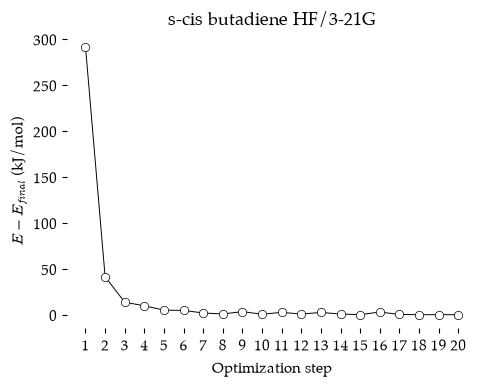

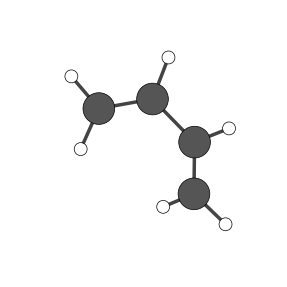

In [5]:
# The s-cis optimization, step by step
ph.plot_history(hist_cis, "s-cis butadiene HF/3-21G")
ph.show_molecule(cis, interactive=INTERACTIVE)

## Scanning the Central Torsion

Freeze the C4&ndash;C3&ndash;C2&ndash;C1 torsion with `frozen_dihedral` and let everything else relax, at a series of angles.

In [6]:
# Freeze the C4-C3-C2-C1 torsion at its starting value in every optimization below
psi4.set_options({"frozen_dihedral": "4 3 2 1"})
(output_dir / "bd_scan").mkdir(exist_ok=True)

angles = [0, 5, 10, 20, 30, 35, 40, 45, 50, 60, 80, 85, 90, 95,
          100, 105, 110, 120, 140, 160, 170, 175, 180]

scan = []          # one row of results per angle
molecules = {}     # the optimized molecule at each angle

for phi in angles:
    psi4.core.clean()
    mol = make_butadiene(phi, tweak=5.0)
    ph.new_output(output_dir / f"bd_scan/bd_{phi:03d}.out")
    E, hist = psi4.optimize("hf/3-21g", molecule=mol, return_history=True)
    scan.append({"Torsion (deg)": phi, "Energy (Eh)": E, "Steps": len(hist["energy"])})
    molecules[phi] = mol
    print(f"{phi:4d} deg   {E:.8f} Eh   {len(hist['energy'])} steps")

Optimizer: Optimization complete!
   0 deg   -154.05394319 Eh   19 steps


Optimizer: Optimization complete!
   5 deg   -154.05399218 Eh   21 steps


Optimizer: Optimization complete!
  10 deg   -154.05413091 Eh   22 steps


Optimizer: Optimization complete!
  20 deg   -154.05457624 Eh   19 steps


Optimizer: Optimization complete!
  30 deg   -154.05500283 Eh   17 steps


Optimizer: Optimization complete!
  35 deg   -154.05511830 Eh   16 steps


... (13 outputs left out)

Optimizer: Optimization complete!
 160 deg   -154.05826886 Eh   21 steps


Optimizer: Optimization complete!
 170 deg   -154.05915347 Eh   18 steps


Optimizer: Optimization complete!
 175 deg   -154.05938027 Eh   18 steps


Optimizer: Optimization complete!
 180 deg   -154.05945655 Eh   19 steps


| Line | Notes |
| :---- | :---- |
| `scan.append({...})` | Stores one **row**: angle, energy and steps. |
| `molecules[phi] = mol` | Keeps each optimized **molecule**. We need the 90&deg; and 100&deg; structures later. |

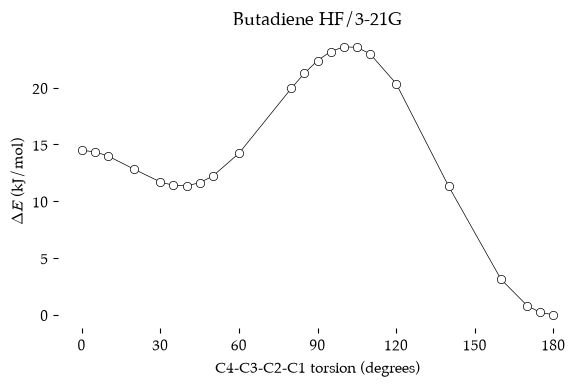

Highest scan point: 100 deg, 23.59 kJ/mol


In [7]:
# The profile, relative to s-trans, in kJ/mol
E_trans = results["s-trans (flat)"]["Energy (Eh)"]
profile = pd.DataFrame(scan)
profile["Delta E (kJ/mol)"] = (profile["Energy (Eh)"] - E_trans) * psi4.constants.hartree2kJmol

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(6,4))
ax.plot(profile["Torsion (deg)"], profile["Delta E (kJ/mol)"], color="black",
        linewidth=0.5, zorder=1)
ax.plot(profile["Torsion (deg)"], profile["Delta E (kJ/mol)"], linestyle="none",
        marker="o", markersize=6, markerfacecolor="white", markeredgecolor="black",
        markeredgewidth=0.5, zorder=2)
ax.set_xticks([0, 30, 60, 90, 120, 150, 180])
ax.set_xlabel("C4-C3-C2-C1 torsion (degrees)")
ax.set_ylabel(r"$\Delta E$ (kJ/mol)")
ax.set_title("Butadiene HF/3-21G")
plt.show()

# The highest point of the scan
top = profile.loc[profile["Energy (Eh)"].idxmax()]
print(f"Highest scan point: {top['Torsion (deg)']:.0f} deg, {top['Delta E (kJ/mol)']:.2f} kJ/mol")

The maximum is not at 90&deg;. It lies between 100&deg; and 105&deg;.

## Finding the Transition State

Start from the 100&deg; scan structure: check for an imaginary frequency, optimize to the saddle point, then check again.

Imaginary frequencies at the guess (cm-1): [-165.26000000]


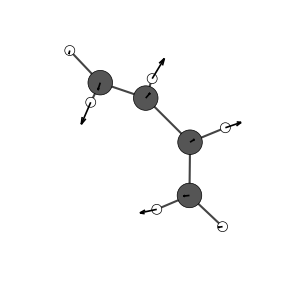

In [8]:
# Clear frozen_dihedral (and every other option), then set scf_type again
psi4.core.clean()
psi4.core.clean_options()
psi4.set_options({"scf_type": "pk"})

# Frequencies at the guess
ts = molecules[100].clone()
ph.new_output(output_dir / "bd_ts_guess_freq.out")
E, wfn_guess = psi4.frequency("hf/3-21g", molecule=ts, return_wfn=True)
freqs = wfn_guess.frequencies().to_array()
print("Imaginary frequencies at the guess (cm-1):", np.round(freqs[freqs < 0], 2))
ph.show_vibration(wfn_guess, 0, interactive=INTERACTIVE)

In [9]:
# Transition state search, starting from the Hessian of the frequency job
psi4.core.clean()
psi4.set_options({"opt_type": "ts", "full_hess_every": 0, "g_convergence": "gau_tight"})
ph.new_output(output_dir / "bd_ts.out")
E, hist = psi4.optimize("hf/3-21g", molecule=ts, return_history=True)
record("transition state", E, ts, len(hist["energy"]))

# Check it: a transition state has exactly one imaginary frequency
psi4.core.clean()
psi4.core.clean_options()
psi4.set_options({"scf_type": "pk"})
ph.new_output(output_dir / "bd_ts_freq.out")
E, wfn_ts = psi4.frequency("hf/3-21g", molecule=ts, return_wfn=True)
freqs = wfn_ts.frequencies().to_array()
print(f"Torsion at the transition state: {results['transition state']['Torsion (deg)']} deg")
print("Imaginary frequencies (cm-1):", np.round(freqs[freqs < 0], 2))

Optimizer: Optimization complete!


Torsion at the transition state: 102.02 deg
Imaginary frequencies (cm-1): [-167.94000000]


| Line | Notes |
| :---- | :---- |
| `"opt_type": "ts"` | Climb **up** along one direction and down along all the others. |
| `"full_hess_every": 0` | Calculate the **Hessian** once at the start, then update it. |
| `"g_convergence": "gau_tight"` | Tighter **convergence** criteria. |
| `freqs[freqs < 0]` | Only the **imaginary** (negative) frequencies. |

## The &pi; Orbitals

Now compare the &pi; system of flat *s-trans*-butadiene with the twisted molecule from the 90&deg; scan point. We run one energy calculation for each, with no symmetry, and pick out the &pi; orbitals.

In [10]:
# Cube files for the orbitals pictures (grid spacing and margin in Bohr)
psi4.set_options({"cubeprop_tasks": ["orbitals"],
                  "cubic_grid_spacing": [0.3, 0.3, 0.3],
                  "cubic_grid_overage": [4.0, 4.0, 4.0]})


def pi_character(wfn, n_orbitals):
    """For the first n_orbitals MOs, the share of their carbon p orbitals that points
    perpendicular to the local plane at each carbon (0 = sigma, 1 = pi)."""
    mol = wfn.molecule()
    xyz = mol.geometry().np                                       # Bohr
    bs = wfn.basisset()
    C = wfn.Ca().np[:, :n_orbitals]                               # MO coefficients
    on_pi = np.zeros(n_orbitals)
    on_p = np.zeros(n_orbitals)
    for i in range(mol.natom()):
        if mol.symbol(i) != "C":
            continue
        # Normal to the plane of this carbon and two of its neighbours
        near = [j for j in range(mol.natom()) if j != i and np.linalg.norm(xyz[j] - xyz[i]) < 3.0]
        n = np.cross(xyz[near[0]] - xyz[i], xyz[near[1]] - xyz[i])
        n = n / np.linalg.norm(n)
        # The p basis functions on this carbon, and which way each one points
        funcs = [k for k in range(bs.nbf()) if bs.function_to_center(k) == i
                 and bs.shell(bs.function_to_shell(k)).am == 1]
        direction = np.zeros((len(funcs), 3))
        for a in range(3):
            step = np.zeros(3)
            step[a] = 0.01
            direction[:, a] = (bs.compute_phi(*(xyz[i] + step)) - bs.compute_phi(*(xyz[i] - step)))[funcs]
        direction = direction / np.linalg.norm(direction, axis=1)[:, None]
        # The p "arrow" of each MO on this carbon, and how much of it lies along the normal
        P = direction.T @ C[funcs, :]
        on_pi += (n @ P) ** 2
        on_p += (P ** 2).sum(axis=0)
    return on_pi / on_p

def oriented_copy(mol):
    """A copy with no symmetry, the C2-C3 bond along x and the C1-C2-C3 plane flat in xy."""
    xyz = mol.geometry().np * psi4.constants.bohr2angstroms
    ex = xyz[2] - xyz[1]
    ex = ex / np.linalg.norm(ex)
    ez = np.cross(xyz[0] - xyz[1], xyz[2] - xyz[1])
    ez = ez / np.linalg.norm(ez)
    new = (xyz - (xyz[1] + xyz[2]) / 2) @ np.array([ex, np.cross(ez, ex), ez]).T
    lines = ["0 1"] + [f"{mol.symbol(i)} {x:.8f} {y:.8f} {z:.8f}" for i, (x, y, z) in enumerate(new)]
    return psi4.geometry("\n".join(lines + ["symmetry c1", "no_reorient", "no_com"]))

def pi_orbitals(name, mol):
    """HF/3-21G energy without symmetry, then the pi MOs: their numbers, energies and cube files."""
    psi4.core.clean()
    mol_c1 = oriented_copy(mol)
    ph.new_output(output_dir / f"bd_{name}_orbitals.out")
    E, wfn = psi4.energy("hf/3-21g", molecule=mol_c1, return_wfn=True)
    n_occ = wfn.nalpha()
    score = pi_character(wfn, n_occ + 6)                          # occupied and 6 empty MOs
    mos = [k + 1 for k in range(len(score)) if score[k] > 0.5]    # numbered from 1
    eps = wfn.epsilon_a().np
    folder = output_dir / f"bd_cube_{name}"
    folder.mkdir(exist_ok=True)
    psi4.set_options({"cubeprop_orbitals": mos, "cubeprop_filepath": str(folder)})
    psi4.cubeprop(wfn)
    cubes = [next(folder.glob(f"Psi_a_{k}_*.cube")) for k in mos]
    table = pd.DataFrame({"MO": mos,
                          "Occupied": ["yes" if k <= n_occ else "no" for k in mos],
                          "Energy (Eh)": [eps[k - 1] for k in mos],
                          "pi character": [score[k - 1] for k in mos]})
    return mol_c1, table, cubes

trans_c1, pi_trans, cubes_trans = pi_orbitals("trans", trans)
twist_c1, pi_twist, cubes_twist = pi_orbitals("090", molecules[90])
print("s-trans"); print(pi_trans.round(4).to_string(index=False))
print("\n90 degrees"); print(pi_twist.round(4).to_string(index=False))

s-trans
 MO Occupied  Energy (Eh)  pi character
 14      yes      -0.4479           1.0
 15      yes      -0.3252           1.0
 16       no       0.1318           1.0
 17       no       0.2706           1.0

90 degrees
 MO Occupied  Energy (Eh)  pi character
 14      yes      -0.3745        0.9622
 15      yes      -0.3701        0.9553
 16       no       0.1808        0.9898
 17       no       0.1851        0.9682


| Line | Notes |
| :---- | :---- |
| `pi_character(wfn, n_orbitals)` | For each MO, how much of its carbon *p* character points **perpendicular** to the local plane at each carbon. &pi; orbitals score near 1, &sigma; orbitals near 0. |
| `bs.compute_phi(x, y, z)` | The value of every **basis function** at one point. We use it to find which way each *p* function points. |
| `score > 0.5` | The MOs we call &pi;. |
| `oriented_copy(mol)` | The same structure with **no symmetry** (so the MOs are numbered in order of energy), turned so that the C2&ndash;C3 bond lies along *x*. Both pictures are then seen from the same direction. |

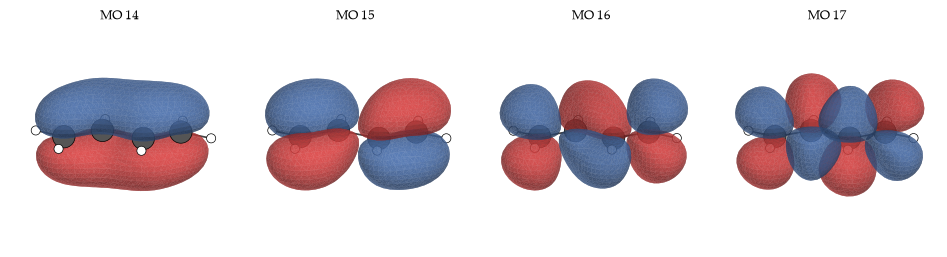

In [11]:
# s-trans: the four pi orbitals, lowest energy first
ph.show_orbitals(cubes_trans, titles=[f"MO {k}" for k in pi_trans["MO"]],
                 mol=trans_c1, isoval=0.03, interactive=INTERACTIVE, elev=20, azim=-60)

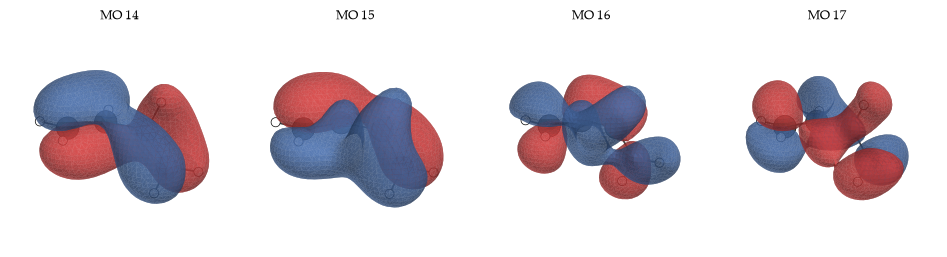

In [12]:
# 90 degrees: the four pi orbitals, lowest energy first
ph.show_orbitals(cubes_twist, titles=[f"MO {k}" for k in pi_twist["MO"]],
                 mol=twist_c1, isoval=0.03, interactive=INTERACTIVE, elev=20, azim=-60)

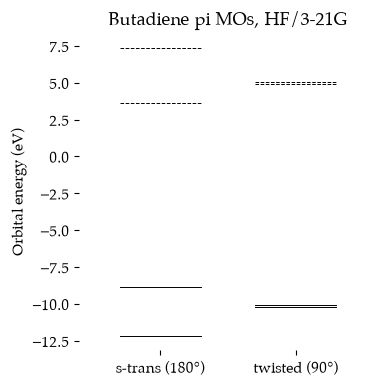

In [13]:
# Orbital energy levels of the pi system, flat and twisted, in eV
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(4,4))
for x, table in [(0, pi_trans), (1, pi_twist)]:
    for _, row in table.iterrows():
        energy = row["Energy (Eh)"] * psi4.constants.hartree2ev
        style = "-" if row["Occupied"] == "yes" else "--"
        ax.plot([x - 0.3, x + 0.3], [energy, energy], color="black",
                linewidth=0.7, linestyle=style)
ax.set_xticks([0, 1])
ax.set_xticklabels(["s-trans (180°)", "twisted (90°)"])
ax.set_xlim(-0.6, 1.6)
ax.set_ylabel("Orbital energy (eV)")
ax.set_title("Butadiene pi MOs, HF/3-21G")
plt.show()

Solid lines are occupied, dashed lines are empty. In the flat molecule the four &pi; orbitals are spread apart. At 90&deg; they come together in **pairs**: two isolated ethylene &pi; bonds.

## Equilibrium and Rate

In [14]:
# Physical constants and temperature
R = 8.314462618e-3      # kJ/(mol K)
kB = 1.380649e-23       # J/K
h = 6.62607015e-34      # J s
T = 298.15              # K

# Energies from the results dictionary, in kJ/mol
to_kJ = psi4.constants.hartree2kJmol
E_cis = results["s-cis"]["Energy (Eh)"]
E_ts = results["transition state"]["Energy (Eh)"]
dE_cis = (E_cis - E_trans) * to_kJ
dE_ts = (E_ts - E_trans) * to_kJ
dE_ts_cis = (E_ts - E_cis) * to_kJ

# Equilibrium constant (x2: two mirror-image s-cis structures) and Eyring rate constants
K = 2 * np.exp(-dE_cis / (R * T))
k_forward = (kB * T / h) * np.exp(-dE_ts / (R * T))
k_reverse = (kB * T / h) * np.exp(-dE_ts_cis / (R * T))

print(f"s-cis - s-trans:      {dE_cis:.2f} kJ/mol")
print(f"Barrier from s-trans: {dE_ts:.2f} kJ/mol")
print(f"Barrier from s-cis:   {dE_ts_cis:.2f} kJ/mol")
print(f"K = [s-cis]/[s-trans] = {K:.4f}   ({100 * K / (1 + K):.1f}% s-cis)")
print(f"k(s-trans -> s-cis) = {k_forward:.2e} per second")
print(f"k(s-cis -> s-trans) = {k_reverse:.2e} per second")

s-cis - s-trans:      11.33 kJ/mol
Barrier from s-trans: 23.63 kJ/mol
Barrier from s-cis:   12.30 kJ/mol
K = [s-cis]/[s-trans] = 0.0207   (2.0% s-cis)
k(s-trans -> s-cis) = 4.50e+08 per second
k(s-cis -> s-trans) = 4.35e+10 per second


## All the Results

In [15]:
# Every stored result in one table, relative to s-trans
summary = pd.DataFrame(results).T
summary["Delta E (kJ/mol)"] = (summary["Energy (Eh)"] - E_trans) * to_kJ

# Save the results and the scan for other pages
summary.to_json(data_dir / "butadiene_results_v2.json", orient="index", indent=2)
profile.to_json(data_dir / "butadiene_scan_v2.json", orient="records", indent=2)
summary

,Energy (Eh),Torsion (deg),Steps,Delta E (kJ/mol)
s-trans (flat),-154.059456,180.00,8.0,0.000000
s-cis (flat),-154.053943,0.00,9.0,14.474404
s-cis,-154.055140,38.15,20.0,11.331740
s-trans (tweaked),-154.059456,-179.98,16.0,-0.000432
transition state,-154.050456,102.02,3.0,23.630924
